In [1]:
!pip install mplfinance

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.0/75.0 kB 2.8 MB/s eta 0:00:00


In [6]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import mplfinance as mpf
import numpy as np

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:
!ls /content/drive/MyDrive/Investment/因子分析

20260820


In [10]:
file_path ='/content/drive/MyDrive/Investment/因子分析/20260820/goog_prices.csv'
df = pd.read_csv(file_path)

/usr/local/lib/python3.13/dist-packages/mplfinance/_arg_validators.py:84: UserWarning: 


            POSSIBLE TO SEE DETAILS (Candles, Ohlc-Bars, Etc.)
   For more information see:
   - https://github.com/matplotlib/mplfinance/wiki/Plotting-Too-Much-Data
   
   TO SILENCE THIS WARNING, set `type='line'` in `mpf.plot()`
   OR set kwarg `warn_too_much_data=N` where N is an integer 
   LARGER than the number of data points you want to plot.

  warnings.warn('\n\n ================================================================= '+


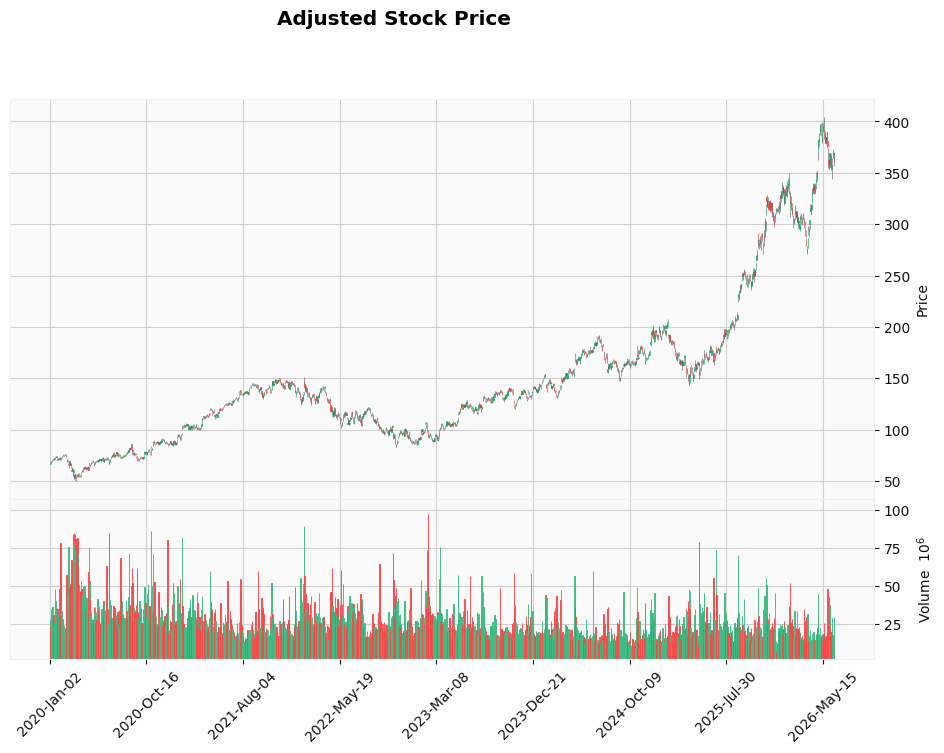

In [11]:
# 1. 確保 'date' 欄位是 datetime 格式，並將其設為 index
df['date'] = pd.to_datetime(df['date'])
df.set_index('date', inplace=True)

# 2. 為了畫圖，我們只取需要的 adj (還原/調整後) 欄位
df_adj = df[['adjOpen', 'adjHigh', 'adjLow', 'adjClose', 'adjVolume']].copy()

# 3. mplfinance 規定欄位名稱必須是首字母大寫的 'Open', 'High', 'Low', 'Close', 'Volume'
df_adj.rename(columns={
    'adjOpen': 'Open',
    'adjHigh': 'High',
    'adjLow': 'Low',
    'adjClose': 'Close',
    'adjVolume': 'Volume'
}, inplace=True)
# 取最後300個datapoint
#df_adj_300 = df_adj.iloc[-300:]

# 4. 繪製 K 線圖 (type='candle' 表示 K線，volume=True 表示要在下方畫成交量)
# style='yahoo' 會套用類似 Yahoo Finance 的紅綠配色 (漲綠跌紅 或 漲紅跌綠 取決於版本預設，通常美股是漲綠跌紅)
mpf.plot(df_adj, type='candle', volume=True, style='yahoo', title='Adjusted Stock Price', figsize=(12, 8))

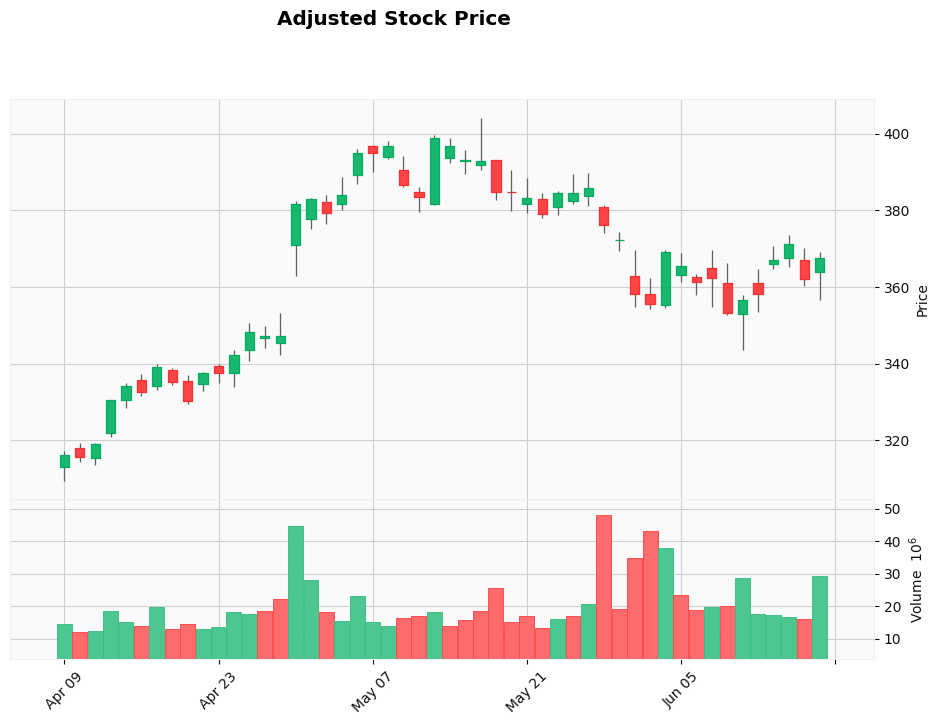

In [12]:
df_adj_50 = df_adj.iloc[-50:]
mpf.plot(df_adj_50, type='candle', volume=True, style='yahoo', title='Adjusted Stock Price', figsize=(12, 8))

In [13]:
df = df.reset_index()

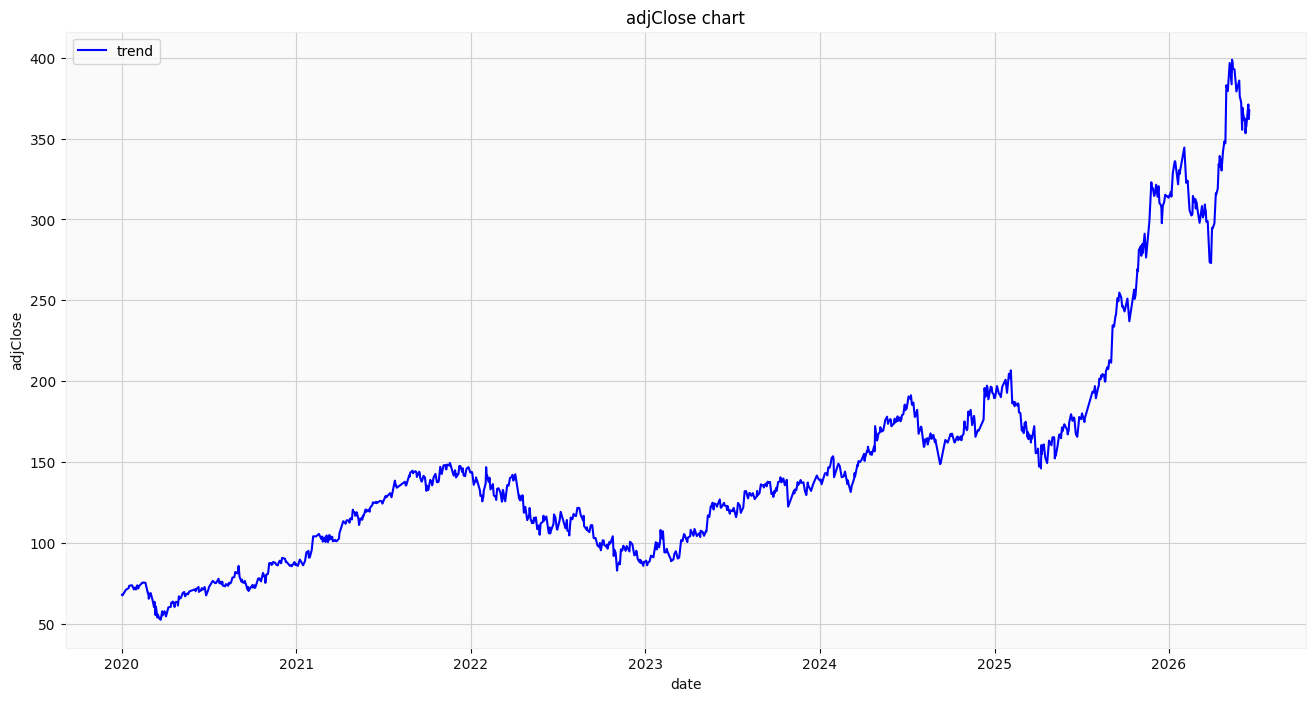

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
df['date'] = pd.to_datetime(df['date'])
plt.figure(figsize=(16, 8))
plt.plot(df['date'], df['adjClose'],  color='b', linestyle='-',label='trend' )


plt.title('adjClose chart')
plt.xlabel('date')
plt.ylabel('adjClose')
plt.grid(True)  # 顯示網格
plt.legend()    # 顯示圖例

# 顯示圖表
plt.show()

每月最低點資料：


,date,adjClose
1,2020-01-03,67.435013
38,2020-02-27,65.325222
55,2020-03-23,52.366633
64,2020-04-03,54.411500
83,2020-05-01,65.450114
...,...,...
1538,2026-02-17,302.428113
1567,2026-03-30,272.973723
1570,2026-04-02,294.280744
1609,2026-05-29,376.200844


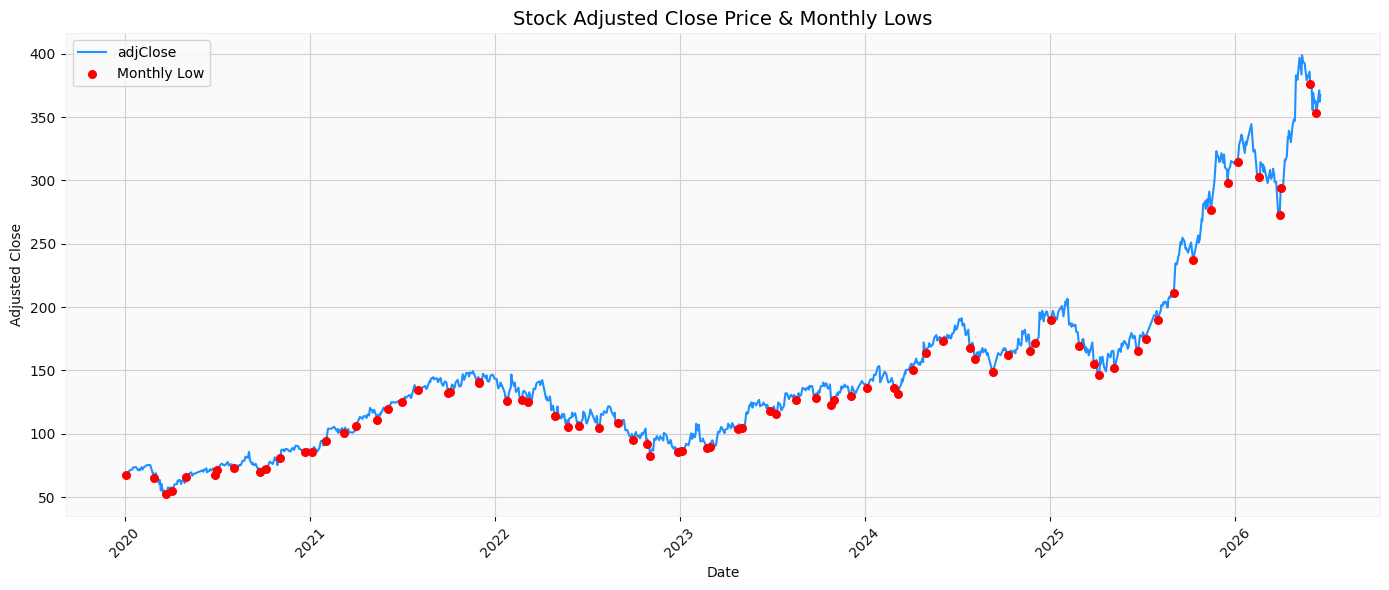

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

# 2. 將 date 欄位轉換為 datetime 格式並排序
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date')

# --------------------------------------------------
# 3. 對全部資料按月份 (M) 找出每月 adjClose 的最低點
# （如果資料時間跨度非常長，想改按年份找最低點，可將 'M' 改為 'Y'）
min_indices = df.groupby(df['date'].dt.to_period('M'))['adjClose'].idxmin()
monthly_min = df.loc[min_indices]

# 印出每月最低點資料確認
print("每月最低點資料：")
display(monthly_min[['date', 'adjClose']])
# --------------------------------------------------

# 4. 繪製圖表
plt.figure(figsize=(14, 6))  # 跨度較長時，稍微拉寬圖表尺寸視覺效果較好

# 繪製全部資料的收盤價折線圖（無圓點）
plt.plot(df['date'], df['adjClose'], color='dodgerblue', linewidth=1.5, label='adjClose')

# 用紅點標示每月最低點
plt.scatter(monthly_min['date'], monthly_min['adjClose'], color='red', s=30, zorder=5, label='每月最低點')

# 在每個最低點下方加上價格標籤


# 圖表細節設定
plt.title('Stock Adjusted Close Price & Monthly Lows', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Adjusted Close')
plt.legend(['adjClose', 'Monthly Low'])
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [16]:
df['mid'] = df['low']+(df['low']+df['high'])/2

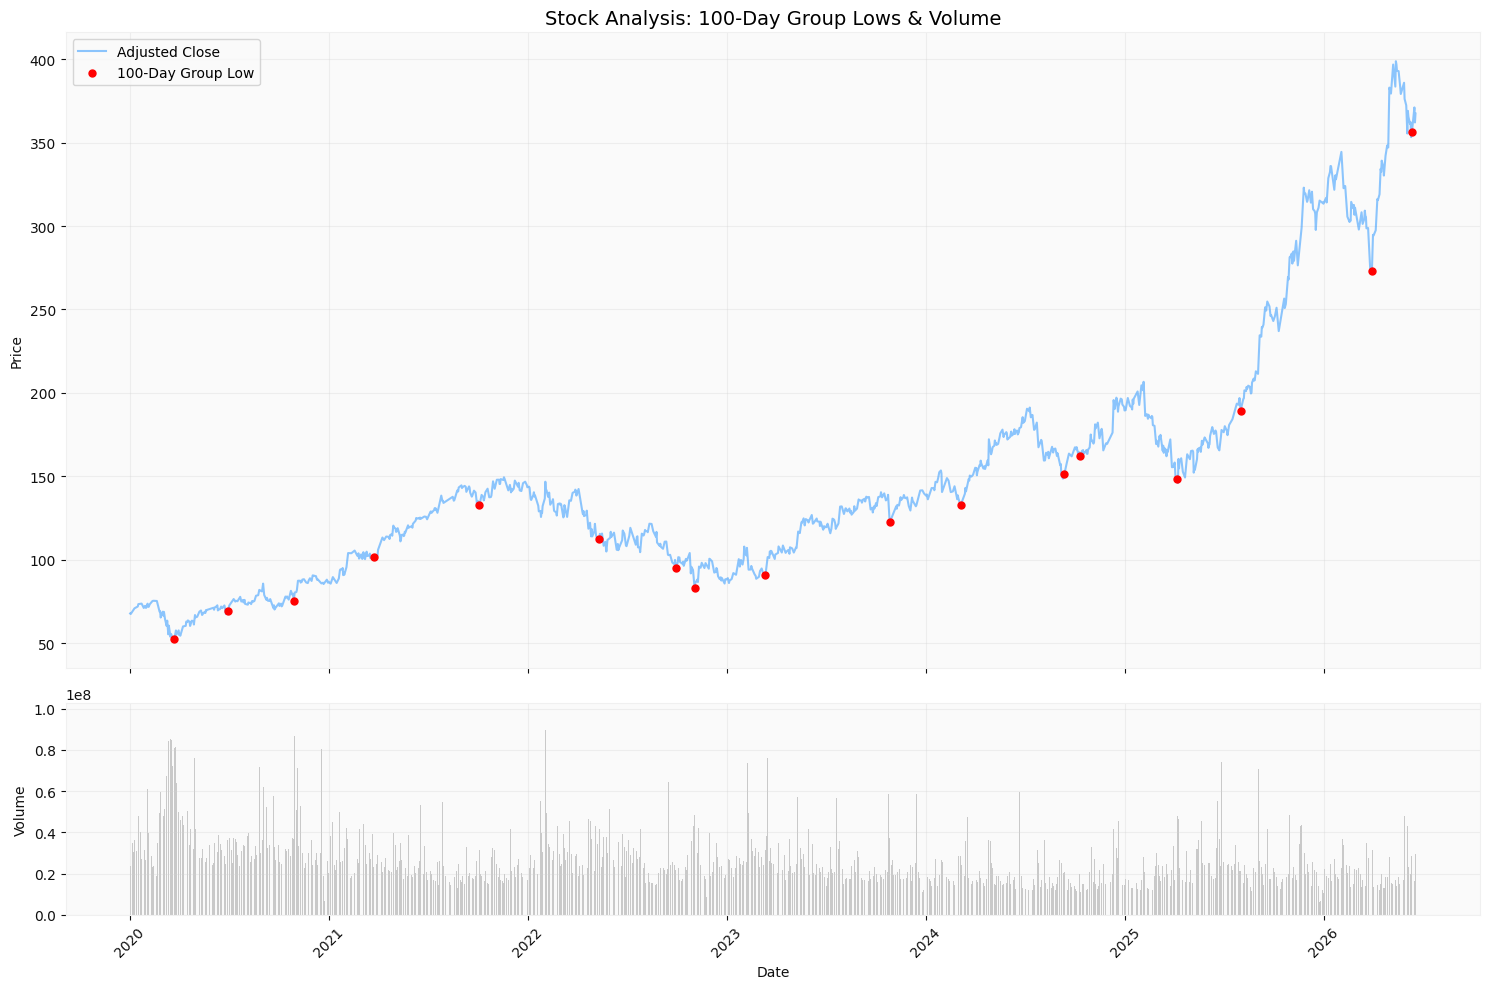

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def plot_stock_analysis(df, n_days=5):
    """
    計算分組最低點並繪製價格與成交量圖表
    """
    # 1. 資料處理：確保日期格式與計算 mid
    plot_df = df.copy()
    plot_df['date'] = pd.to_datetime(plot_df['date'])
    if 'mid' not in plot_df.columns:
        plot_df['mid'] = plot_df['adjLow'] + (plot_df['adjHigh'] - plot_df['adjLow']) / 2

    # 2. 計算分組最低點 (每 n_days 一組)
    group_key = np.arange(len(plot_df)) // n_days
    min_indices = plot_df.groupby(group_key)['mid'].idxmin()
    min_rows = plot_df.loc[min_indices]

    # 3. 建立畫布與子圖 (2x1, 高度比 3:1)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10), sharex=True,
                                   gridspec_kw={'height_ratios': [3, 1]})

    # 上圖：價格與最低點標記
    ax1.plot(plot_df['date'], plot_df['adjClose'], color='dodgerblue', alpha=0.5, label='Adjusted Close')
    ax1.scatter(min_rows['date'], min_rows['adjClose'], color='red', s=25, zorder=5, label=f'{n_days}-Day Group Low')
    ax1.set_title(f'Stock Analysis: {n_days}-Day Group Lows & Volume', fontsize=14)
    ax1.set_ylabel('Price')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # 下圖：成交量
    ax2.bar(plot_df['date'], plot_df['adjVolume'], color='gray', alpha=0.4, label='Volume')
    ax2.set_ylabel('Volume')
    ax2.set_xlabel('Date')
    ax2.grid(True, alpha=0.3)

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    return min_indices

# 執行函式，設定 N=5
min_indices = plot_stock_analysis(df, n_days=100)

In [18]:
df.iloc[min_indices]

,date,close,high,low,open,volume,adjClose,adjHigh,adjLow,adjOpen,adjVolume,divCash,splitFactor,mid
55,2020-03-23,1056.62,1071.3200,1013.536,1061.320,4044137,52.366633,53.095173,50.231368,52.599568,80882740,0.0,1.0,2055.96400
123,2020-06-29,1394.97,1395.6000,1347.010,1358.180,1810180,69.135434,69.166657,66.758512,67.312103,36203600,0.0,1.0,2718.31500
208,2020-10-28,1516.62,1561.3500,1514.620,1559.740,1833959,75.164471,77.381313,75.065350,77.301520,36679180,0.0,1.0,3052.60500
309,2021-03-25,2044.36,2058.8700,2010.730,2044.810,1418907,101.319538,102.038661,99.652818,101.341840,28378140,0.0,1.0,4045.53000
442,2021-10-04,2675.30,2714.0000,2623.330,2713.990,1576495,132.589251,134.507243,130.013590,134.506747,31529900,0.0,1.0,5291.99500
595,2022-05-12,2263.22,2297.1300,2202.270,2238.760,2073244,112.166353,113.846950,109.145639,110.954103,41464880,0.0,1.0,4451.97000
692,2022-09-30,96.15,99.4940,96.030,97.730,26277832,95.304874,98.619481,95.185929,96.870986,26277832,0.0,1.0,193.79200
716,2022-11-03,83.49,86.5500,83.450,86.345,48510364,82.756151,85.789255,82.716502,85.586056,48510364,0.0,1.0,168.45000
803,2023-03-13,91.66,93.0800,89.940,90.565,31508570,90.854339,92.261858,89.149458,89.768964,31508570,0.0,1.0,181.45000
962,2023-10-27,123.40,124.4400,121.460,124.030,37367673,122.315355,123.346214,120.392407,122.939818,37367673,0.0,1.0,244.41000


In [ ]:
df

,date,close,high,low,open,volume,adjClose,adjHigh,adjLow,adjOpen,adjVolume,divCash,splitFactor,mid
0,2020-01-02,1367.37,1368.1400,1341.5500,1341.550,1406731,67.767564,67.805725,66.487911,66.487911,28134620,0.0,1.0,2696.39500
1,2020-01-03,1360.66,1372.5000,1345.5440,1347.860,1187006,67.435013,68.021809,66.685856,66.800638,23740120,0.0,1.0,2704.56600
2,2020-01-06,1394.21,1396.5000,1350.0000,1350.000,1733149,69.097768,69.211262,66.906698,66.906698,34662980,0.0,1.0,2723.25000
3,2020-01-07,1393.34,1402.9900,1390.3800,1397.940,1511693,69.054650,69.532909,68.907951,69.282629,30233860,0.0,1.0,2787.06500
4,2020-01-08,1404.32,1411.5800,1390.8400,1392.080,1529177,69.598825,69.958634,68.930749,68.992204,30583540,0.0,1.0,2792.05000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1619,2026-06-12,358.16,364.7725,353.3400,361.100,17657657,358.160000,364.772500,353.340000,361.100000,17657657,0.0,1.0,712.39625
1620,2026-06-15,367.11,370.6500,364.6500,365.990,17268649,367.110000,370.650000,364.650000,365.990000,17268649,0.0,1.0,732.30000
1621,2026-06-16,371.10,373.6000,365.3200,367.465,16492788,371.100000,373.600000,365.320000,367.465000,16492788,0.0,1.0,734.78000
1622,2026-06-17,362.10,370.1500,360.2300,367.050,16003508,362.100000,370.150000,360.230000,367.050000,16003508,0.0,1.0,725.42000


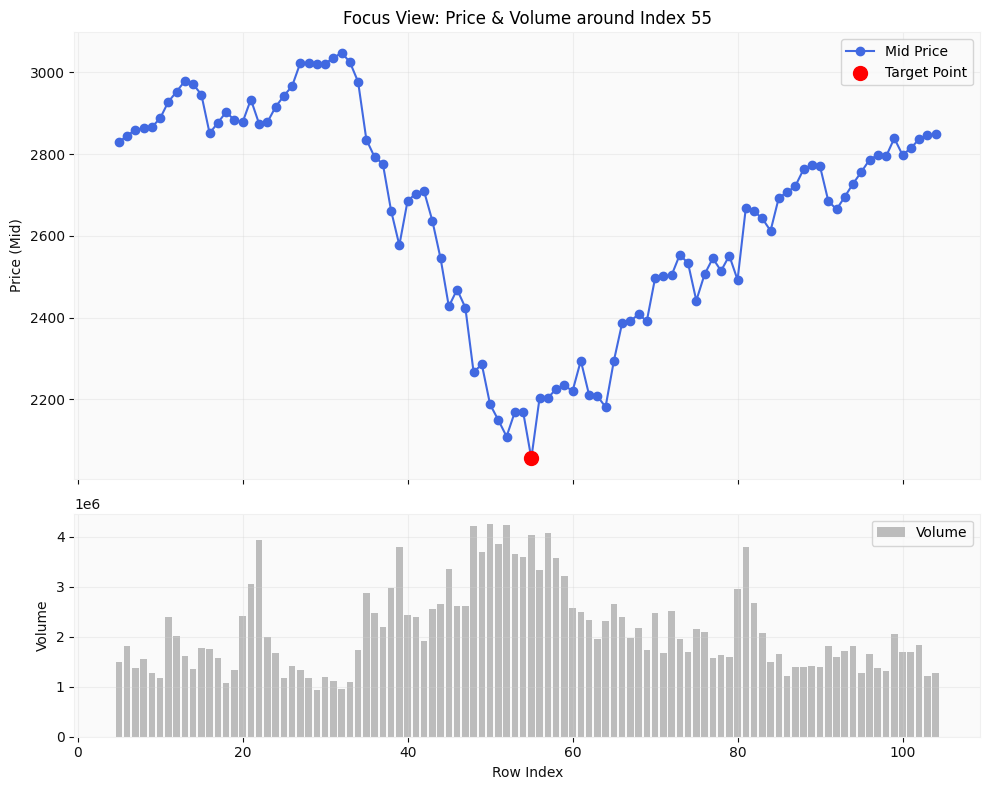

In [ ]:
def plot_prices_and_volume(df, row_idx, offset):
    """
    針對指定的 row_idx，取出前後 10 天的資料並繪製價格與成交量子圖
    """
    # 1. 取得範圍 (確保不超出索引範圍)
    start_idx = max(0, row_idx - offset)
    end_idx = min(len(df), row_idx + offset)
    subset = df.iloc[start_idx:end_idx]

    # 2. 建立上下兩個子圖
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True,
                                   gridspec_kw={'height_ratios': [2, 1]})

    # 上圖：繪製價格 (mid)
    ax1.plot(subset.index, subset['mid'], marker='o', color='royalblue', label='Mid Price')
    # 標註指定的中心點
    ax1.scatter(row_idx, df.loc[row_idx, 'mid'], color='red', s=100, zorder=5, label='Target Point')
    ax1.set_title(f'Focus View: Price & Volume around Index {row_idx}')
    ax1.set_ylabel('Price (Mid)')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # 下圖：繪製成交量 (volume)
    # 注意：這裡使用 df 中的 volume 欄位
    ax2.bar(subset.index, subset['volume'], color='gray', alpha=0.5, label='Volume')
    ax2.set_ylabel('Volume')
    ax2.set_xlabel('Row Index')
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_prices_and_volume(df, min_indices.iloc[0], 50)

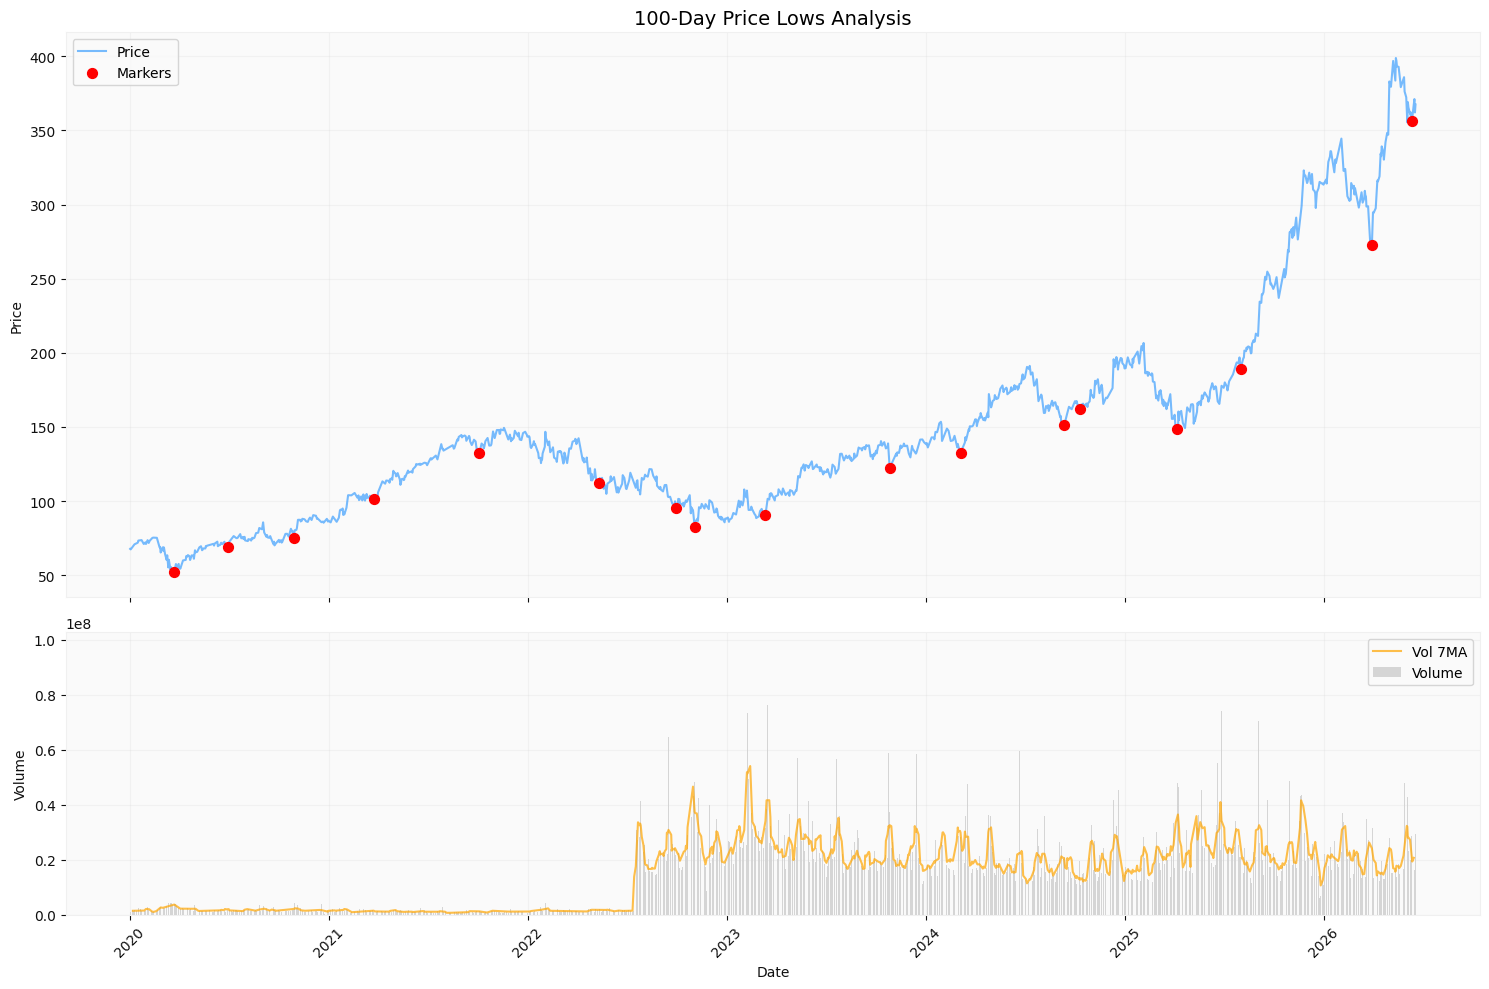

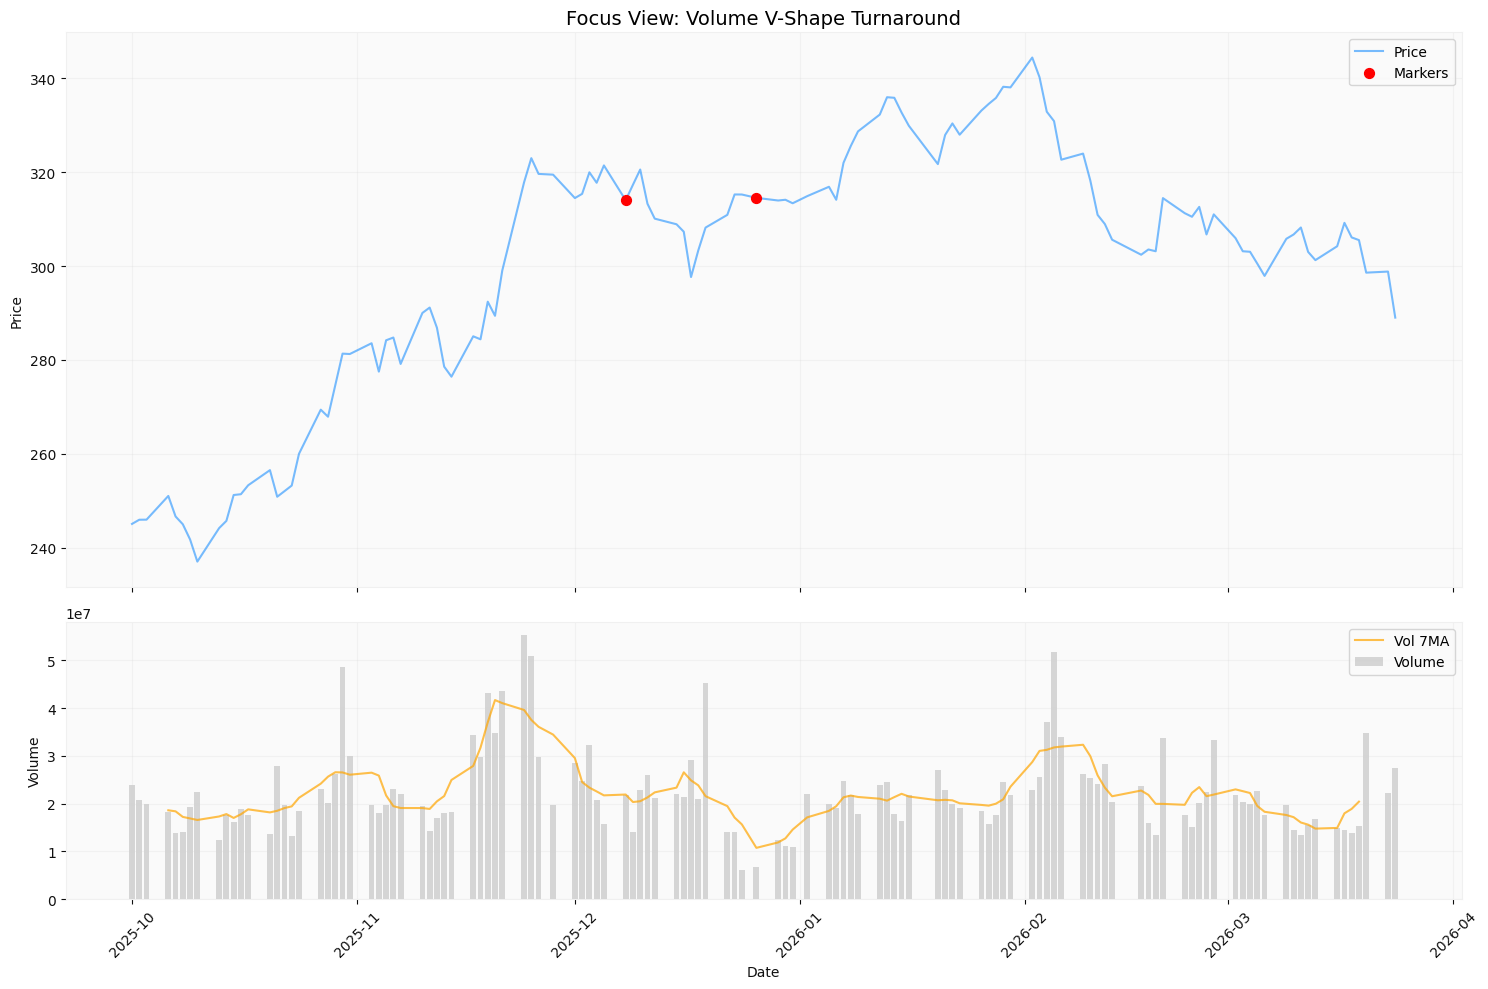

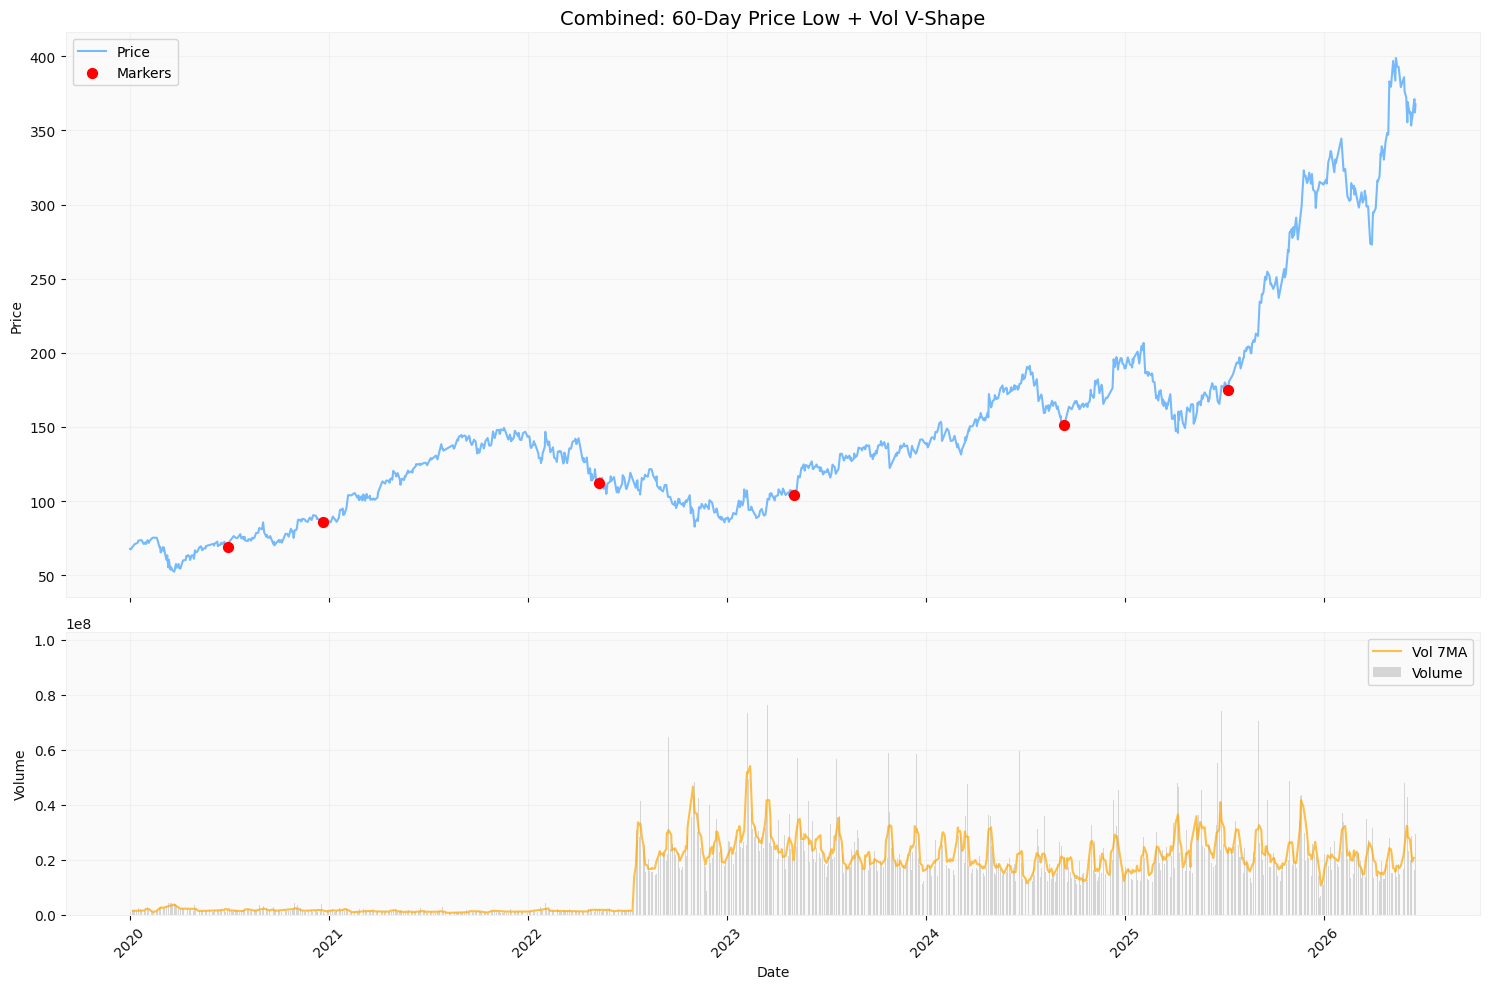

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def find_market_indices(df, method='price_low', n_days=60, prominence=0.2, window=5, tolerance=3):
    """
    整合型分析函式：回傳指定的市場索引
    method: 'price_low', 'vol_low', 'vol_v_shape', 'combined'
    tolerance: 當 method='combined' 時，價格低點與量縮點允許的時間差 (天數)
    """
    temp_df = df.copy()
    if 'mid' not in temp_df.columns:
        temp_df['mid'] = temp_df['adjLow'] + (temp_df['adjHigh'] - temp_df['adjLow']) / 2

    if method == 'price_low':
        group_key = np.arange(len(temp_df)) // n_days
        return temp_df.groupby(group_key)['mid'].idxmin().values

    elif method == 'vol_low':
        group_key = np.arange(len(temp_df)) // n_days
        return temp_df.groupby(group_key)['volume'].idxmin().values

    elif method == 'vol_v_shape':
        temp_df['vol_smooth'] = temp_df['volume'].rolling(window=3, center=True).mean()
        v_indices = []
        for i in range(window, len(temp_df) - window):
            mid = temp_df.iloc[i]['vol_smooth']
            left = temp_df.iloc[i-window:i]['vol_smooth'].mean()
            right = temp_df.iloc[i+1:i+window+1]['vol_smooth'].mean()
            if mid < left * (1 - prominence) and mid < right * (1 - prominence):
                if mid == temp_df.iloc[i-window:i+window+1]['vol_smooth'].min():
                    v_indices.append(i)
        return np.array(v_indices)

    elif method == 'combined':
        # 1. 取得價格低點 (例如 60 天區間)
        p_indices = find_market_indices(df, method='price_low', n_days=n_days)
        # 2. 取得成交量 V 型低點
        v_indices = find_market_indices(df, method='vol_v_shape', prominence=prominence, window=window)

        # 3. 找出在 tolerance 天數內同時滿足的交集點
        combined = []
        for p in p_indices:
            for v in v_indices:
                if abs(p - v) <= tolerance:
                    combined.append(p)
                    break
        return np.array(combined)

def plot_market_analysis(df, target_indices, title="Market Analysis", window_size=None, focus_idx=None):
    """
    整合型繪圖函式：繪製價格與成交量，並標註特定索引點
    window_size: 若提供，則只顯示 focus_idx 前後的天數
    """
    plot_df = df.copy()
    plot_df['date'] = pd.to_datetime(plot_df['date'])

    if focus_idx is not None and window_size is not None:
        start = max(0, focus_idx - window_size)
        end = min(len(plot_df), focus_idx + window_size)
        plot_df = plot_df.iloc[start:end]

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10), sharex=True, gridspec_kw={'height_ratios': [2, 1]})

    # 價格子圖
    ax1.plot(plot_df['date'], plot_df['adjClose'], color='dodgerblue', alpha=0.6, label='Price')
    valid_p_indices = [i for i in target_indices if i in plot_df.index]
    ax1.scatter(df.loc[valid_p_indices, 'date'], df.loc[valid_p_indices, 'adjClose'], color='red', s=50, zorder=5, label='Markers')
    ax1.set_title(title, fontsize=14)
    ax1.set_ylabel('Price')
    ax1.legend()
    ax1.grid(True, alpha=0.2)

    # 成交量子圖
    ax2.bar(plot_df['date'], plot_df['volume'], color='gray', alpha=0.3, label='Volume')
    ax2.plot(plot_df['date'], plot_df['volume'].rolling(7, center=True).mean(), color='orange', alpha=0.7, label='Vol 7MA')
    ax2.set_ylabel('Volume')
    ax2.set_xlabel('Date')
    ax2.legend()
    ax2.grid(True, alpha=0.2)

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# --- 使用範例 ---
# 1. 找價格低點並畫全圖
lows = find_market_indices(df, method='price_low', n_days=100)
plot_market_analysis(df, lows, title="100-Day Price Lows Analysis")

# 2. 找成交量 V 型轉折並針對最後一個點放大觀察
v_shapes = find_market_indices(df, method='vol_v_shape', prominence=0.2)
if len(v_shapes) > 0:
    plot_market_analysis(df, v_shapes, title="Focus View: Volume V-Shape Turnaround", window_size=60, focus_idx=v_shapes[-1])

# ================= 使用範例 =================
# 跑多因子交集（60天價格低點 + 成交量 V 型轉折，容許誤差 3 天）
combined_lows = find_market_indices(df, method='combined', n_days=60, prominence=0.2, window=5, tolerance=3)
plot_market_analysis(df, combined_lows, title="Combined: 60-Day Price Low + Vol V-Shape")

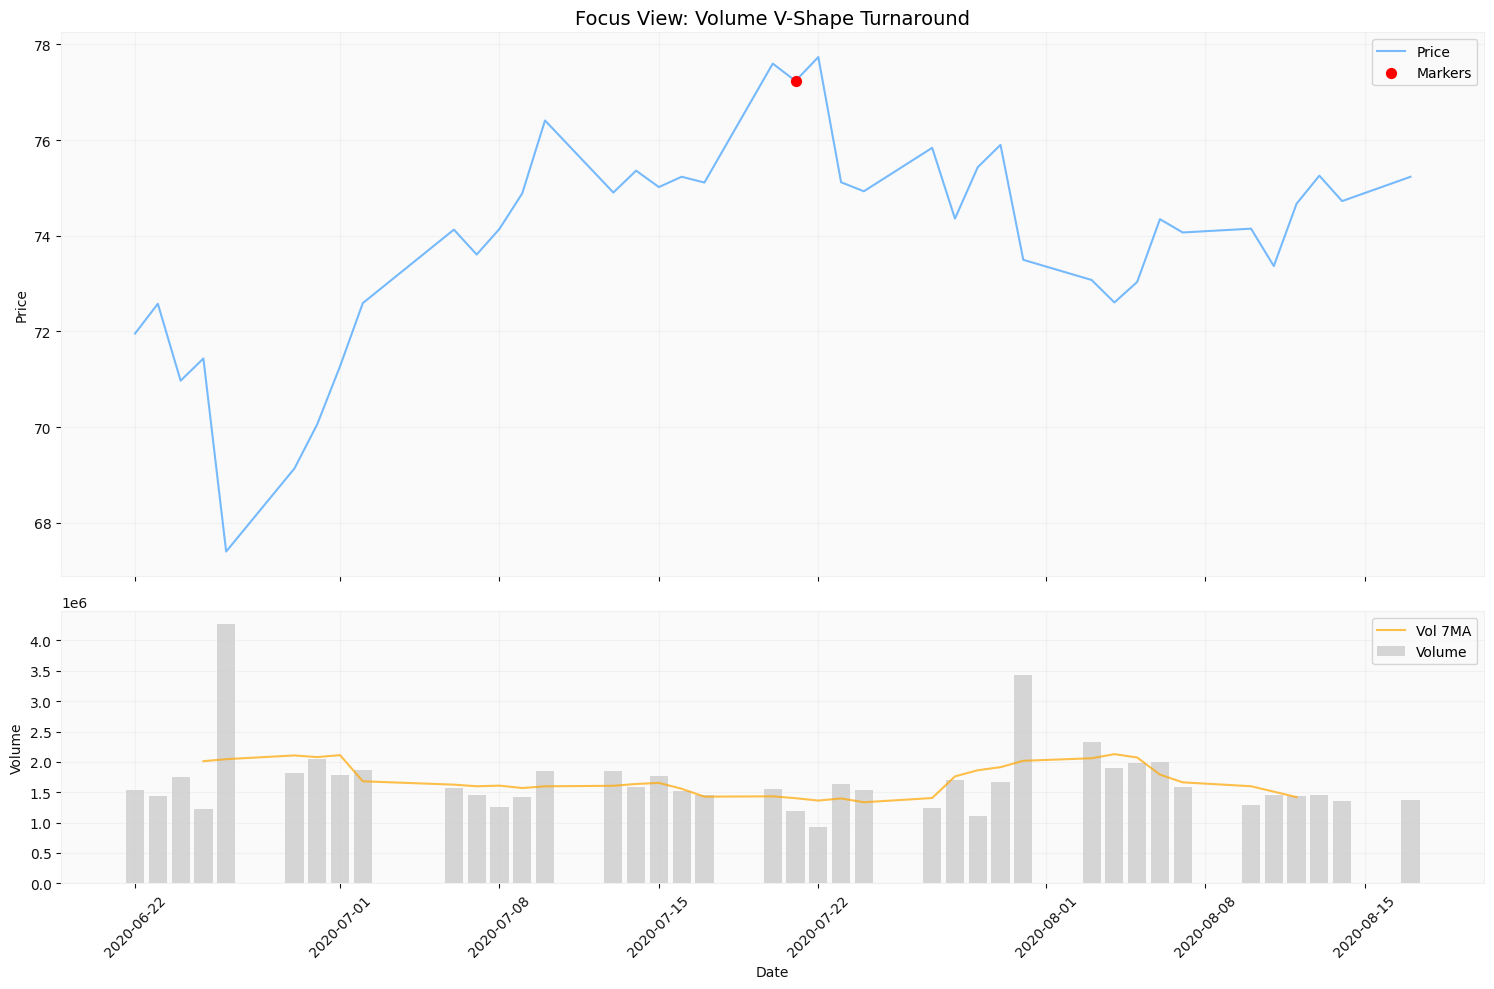

In [ ]:
v_shapes = find_market_indices(df, method='vol_v_shape', prominence=0.3, window=30)
plot_market_analysis(df, v_shapes, title="Focus View: Volume V-Shape Turnaround", window_size=20, focus_idx=v_shapes[1])

In [ ]:
import os
import matplotlib.pyplot as plt

def batch_save_plots(df, method, param_list, offset=20):
    """
    批次處理並存檔的函式
    method: 'price_low', 'vol_low', 'vol_v_shape'
    param_list: 對應 method 的參數列表 (window size 或 prominence)
    offset: 前後天數
    """
    base_dir = f"analysis_plots/{method}"
    if not os.path.exists(base_dir):
        os.makedirs(base_dir)

    for p in param_list:
        # 根據 method 尋找索引
        if method in ['price_low', 'vol_low']:
            indices = find_market_indices(df, method=method, n_days=p)
            title_prefix = f"{method}_win{p}"
        else: # vol_v_shape
            indices = find_market_indices(df, method=method, prominence=p, window=10)
            title_prefix = f"{method}_prom{p}"

        print(f"Processing {method} with param {p}, found {len(indices)} points...")

        # 針對找到的每個點繪圖並存檔
        for i, idx in enumerate(indices):
            # 確保索引在範圍內，並跳過太靠近邊界的點以確保畫得出前後 offset 天
            if idx < offset or idx > len(df) - offset:
                continue

            # 建立圖表
            plot_df = df.iloc[idx-offset : idx+offset].copy()
            plot_df['date'] = pd.to_datetime(plot_df['date'])

            fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw={'height_ratios': [2, 1]})

            # 價格子圖
            ax1.plot(plot_df['date'], plot_df['adjClose'], color='dodgerblue', marker='.', alpha=0.6)
            ax1.scatter(df.loc[idx, 'date'], df.loc[idx, 'adjClose'], color='red', s=100, zorder=5)
            ax1.set_title(f"{title_prefix} - Point {i} (Index {idx})")
            ax1.set_ylabel('Price')
            ax1.grid(True, alpha=0.2)

            # 成交量子圖
            ax2.bar(plot_df['date'], plot_df['volume'], color='gray', alpha=0.3)
            ax2.set_ylabel('Volume')
            ax2.set_xlabel('Date')
            ax2.grid(True, alpha=0.2)

            plt.xticks(rotation=45)
            plt.tight_layout()

            # 存檔
            filename = f"{base_dir}/{title_prefix}_pt{i}_idx{idx}.png"
            plt.savefig(filename)
            plt.close(fig) # 關閉以節省記憶體

# 1. 執行價格與成交量最低點 (Window: 10, 50, 100)
batch_save_plots(df, 'price_low', [10, 50, 100])
batch_save_plots(df, 'vol_low', [10, 50, 100])

# 2. 執行成交量 V 型轉折 (Prominence: 0.2, 0.5, 0.8)
batch_save_plots(df, 'vol_v_shape', [0.2, 0.5, 0.8])

print("所有分析圖表已存檔至 analysis_plots 資料夾中。")

Processing price_low with param 10, found 163 points...
Processing price_low with param 50, found 33 points...
Processing price_low with param 100, found 17 points...
Processing vol_low with param 10, found 163 points...
Processing vol_low with param 50, found 33 points...
Processing vol_low with param 100, found 17 points...
Processing vol_v_shape with param 0.2, found 35 points...
Processing vol_v_shape with param 0.5, found 1 points...
Processing vol_v_shape with param 0.8, found 0 points...
所有分析圖表已存檔至 analysis_plots 資料夾中。


In [ ]:
def find_consecutive_drops(df, n_days=5):
    """
    尋找連續 n_days 天下跌的情況 (non-overlapping)
    """
    close = df['adjClose'].values
    indices = []
    i = 1
    while i < len(df):
        count = 0
        # 檢查是否連續下跌
        while i < len(df) and close[i] < close[i-1]:
            count += 1
            i += 1
            if count == n_days:
                indices.append(i - 1)
                # 為了避免重疊，跳過已計算的區段
                break
        i += 1
    return np.array(indices)

def find_price_drawdowns(df, window=5, threshold=0.05):
    """
    尋找短時間 (window) 內跌幅超過 threshold 的點 (non-overlapping)
    """
    close = df['adjClose'].values
    indices = []
    last_idx = -1

    for i in range(window, len(df)):
        # 計算 window 內的跌幅
        start_price = close[i-window]
        end_price = close[i]
        change = (end_price - start_price) / start_price

        if change <= -threshold:
            # 確保不與上一個點重疊 (至少隔一個 window)
            if i > last_idx + window:
                indices.append(i)
                last_idx = i
    return np.array(indices)

def batch_save_custom_logic(df, offset=20):
    # 1. 連續下跌邏輯
    for n in [5, 10, 15]:
        indices = find_consecutive_drops(df, n_days=n)
        save_path = f"analysis_plots/consecutive_drop/n{n}"
        if not os.path.exists(save_path): os.makedirs(save_path)

        print(f"Consecutive {n} days drop: found {len(indices)} points.")
        for i, idx in enumerate(indices):
            if idx < offset or idx > len(df) - offset: continue
            plot_and_save(df, idx, offset, f"Consecutive_{n}d_Drop_pt{i}", save_path)

    # 2. 短時間跌幅邏輯
    params = [
        (5, 0.05), (5, 0.1), (5, 0.2),
        (10, 0.05), (10, 0.1), (10, 0.2),
        (20, 0.05), (20, 0.1), (20, 0.2),
        (30, 0.05), (30, 0.1), (30, 0.2)
    ]
    for win, thr in params:
        indices = find_price_drawdowns(df, window=win, threshold=thr)
        save_path = f"analysis_plots/drawdown/win{win}_thr{int(thr*100)}"
        if not os.path.exists(save_path): os.makedirs(save_path)

        print(f"Drawdown (Win:{win}, Thr:{thr}): found {len(indices)} points.")
        for i, idx in enumerate(indices):
            if idx < offset or idx > len(df) - offset: continue
            plot_and_save(df, idx, offset, f"Drawdown_{win}d_{int(thr*100)}pct_pt{i}", save_path)

def plot_and_save(df, idx, offset, title_suffix, save_dir):
    subset = df.iloc[idx-offset : idx+offset].copy()
    subset['date'] = pd.to_datetime(subset['date'])

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
    ax1.plot(subset['date'], subset['adjClose'], marker='.', color='blue', alpha=0.5)
    ax1.scatter(df.loc[idx, 'date'], df.loc[idx, 'adjClose'], color='red', s=80, zorder=5)
    ax1.set_title(title_suffix)
    ax1.grid(True, alpha=0.2)

    ax2.bar(subset['date'], subset['volume'], color='gray', alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(f"{save_dir}/{title_suffix}.png")
    plt.close(fig)

# 執行批次儲存
batch_save_custom_logic(df)
print("新邏輯圖表存檔完成。")

Consecutive 5 days drop: found 11 points.
Consecutive 10 days drop: found 0 points.
Consecutive 15 days drop: found 0 points.
Drawdown (Win:5, Thr:0.05): found 52 points.
Drawdown (Win:5, Thr:0.1): found 8 points.
Drawdown (Win:5, Thr:0.2): found 0 points.
Drawdown (Win:10, Thr:0.05): found 42 points.
Drawdown (Win:10, Thr:0.1): found 15 points.
Drawdown (Win:10, Thr:0.2): found 1 points.
Drawdown (Win:20, Thr:0.05): found 28 points.
Drawdown (Win:20, Thr:0.1): found 16 points.
Drawdown (Win:20, Thr:0.2): found 1 points.
Drawdown (Win:30, Thr:0.05): found 23 points.
Drawdown (Win:30, Thr:0.1): found 14 points.
Drawdown (Win:30, Thr:0.2): found 3 points.
新邏輯圖表存檔完成。


In [20]:
import os
import matplotlib.pyplot as plt
import pandas as pd

def batch_save_combined_plots(df, n_days_list, prominence_list, window=5, tolerance=3, offset=20):
    """
    專為 'combined' (多因子交集) 設計的批次存檔函式
    n_days_list: 價格低點的觀察天數列表 (例如 [60, 100])
    prominence_list: 量縮顯著度的列表 (例如 [0.2, 0.5])
    """
    method = 'combined'
    base_dir = f"analysis_plots/{method}"

    # 確保資料夾存在
    if not os.path.exists(base_dir):
        os.makedirs(base_dir)

    # 針對不同的 n_days 與 prominence 進行排列組合測試
    for n_days in n_days_list:
        for prom in prominence_list:

            # 取得交集點索引
            indices = find_market_indices(df, method=method, n_days=n_days, prominence=prom, window=window, tolerance=tolerance)
            title_prefix = f"{method}_ndays{n_days}_prom{prom}_tol{tolerance}"

            print(f"Processing {method} (n_days={n_days}, prom={prom}), found {len(indices)} points...")

            # 針對找到的每個點繪圖並存檔
            for i, idx in enumerate(indices):
                # 確保索引在範圍內，並跳過太靠近邊界的點以確保畫得出前後 offset 天
                if idx < offset or idx > len(df) - offset:
                    continue

                # 建立圖表用的 DataFrame
                plot_df = df.iloc[idx-offset : idx+offset].copy()
                plot_df['date'] = pd.to_datetime(plot_df['date'])

                fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw={'height_ratios': [2, 1]})

                # --- 價格子圖 ---
                ax1.plot(plot_df['date'], plot_df['adjClose'], color='dodgerblue', marker='.', alpha=0.6)
                # 交集點改用紅色大星星標示
                ax1.scatter(df.loc[idx, 'date'], df.loc[idx, 'adjClose'], color='red', marker='*', s=200, zorder=5, edgecolor='black')
                ax1.set_title(f"{title_prefix} - Point {i} (Index {idx})")
                ax1.set_ylabel('Price')
                ax1.grid(True, alpha=0.2)

                # --- 成交量子圖 ---
                ax2.bar(plot_df['date'], plot_df['volume'], color='gray', alpha=0.3)
                ax2.set_ylabel('Volume')
                ax2.set_xlabel('Date')
                ax2.grid(True, alpha=0.2)

                plt.xticks(rotation=45)
                plt.tight_layout()

                # 存檔
                filename = f"{base_dir}/{title_prefix}_pt{i}_idx{idx}.png"
                plt.savefig(filename)
                plt.close(fig) # 關閉以節省記憶體

# ================= 使用範例 =================
# 假設你要測試 60天與100天的價格低點，配上 0.2與0.5的量縮比例
batch_save_combined_plots(
    df=df,
    n_days_list=[60, 100],
    prominence_list=[0.2, 0.5],
    window=5,      # 左右看5天平均
    tolerance=3,   # 容許價跌跟量縮差3天
    offset=30      # 畫出該點前後 30 天的 K 線圖方便觀察
)

print("Combined 分析圖表已全部存檔完成！")

Processing combined (n_days=60, prom=0.2), found 6 points...
Processing combined (n_days=60, prom=0.5), found 0 points...
Processing combined (n_days=100, prom=0.2), found 4 points...
Processing combined (n_days=100, prom=0.5), found 0 points...
Combined 分析圖表已全部存檔完成！


In [21]:
!zip -r combined.zip analysis_plots/
from google.colab import files
files.download('combined.zip')

  adding: analysis_plots/ (stored 0%)
  adding: analysis_plots/combined/ (stored 0%)
  adding: analysis_plots/combined/combined_ndays60_prom0.2_tol3_pt3_idx840.png (deflated 11%)
  adding: analysis_plots/combined/combined_ndays60_prom0.2_tol3_pt5_idx1384.png (deflated 11%)
  adding: analysis_plots/combined/combined_ndays60_prom0.2_tol3_pt1_idx245.png (deflated 11%)
  adding: analysis_plots/combined/combined_ndays100_prom0.2_tol3_pt2_idx595.png (deflated 11%)
  adding: analysis_plots/combined/combined_ndays100_prom0.2_tol3_pt1_idx208.png (deflated 11%)
  adding: analysis_plots/combined/combined_ndays100_prom0.2_tol3_pt3_idx1180.png (deflated 9%)
  adding: analysis_plots/combined/combined_ndays100_prom0.2_tol3_pt0_idx123.png (deflated 10%)
  adding: analysis_plots/combined/combined_ndays60_prom0.2_tol3_pt0_idx123.png (deflated 10%)
  adding: analysis_plots/combined/combined_ndays60_prom0.2_tol3_pt4_idx1180.png (deflated 9%)
  adding: analysis_plots/combined/combined_ndays60_prom0.2_tol3_

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!zip -r analysis_plots.zip analysis_plots/

  adding: analysis_plots/ (stored 0%)
  adding: analysis_plots/price_low/ (stored 0%)
  adding: analysis_plots/price_low/price_low_win50_pt19_idx962.png (deflated 11%)
  adding: analysis_plots/price_low/price_low_win10_pt8_idx80.png (deflated 13%)
  adding: analysis_plots/price_low/price_low_win10_pt75_idx759.png (deflated 12%)
  adding: analysis_plots/price_low/price_low_win10_pt127_idx1274.png (deflated 12%)
  adding: analysis_plots/price_low/price_low_win10_pt153_idx1538.png (deflated 12%)
  adding: analysis_plots/price_low/price_low_win10_pt121_idx1211.png (deflated 12%)
  adding: analysis_plots/price_low/price_low_win50_pt2_idx123.png (deflated 12%)
  adding: analysis_plots/price_low/price_low_win50_pt22_idx1148.png (deflated 12%)
  adding: analysis_plots/price_low/price_low_win10_pt125_idx1251.png (deflated 12%)
  adding: analysis_plots/price_low/price_low_win50_pt29_idx1451.png (deflated 13%)
  adding: analysis_plots/price_low/price_low_win10_pt150_idx1500.png (deflated 12%)
  a